In [ ]:
NAME = ""
ID = ""

---

# Pandas 
*© 2018-current, authors at Computer Science and Technology, Division of Science and Technology, BNU-HKBU United International College*

The version was created by Dr. Xinzhi Zhang (Hong Kong Baptist University), modified by Dr. Jefferson Fong, Prof. Weifeng SU and Dr. Bingqing QU (BNBU).

After this class, you will know a new data structure DataFrame (Series) defined by **Pandas**.

## 1. What is Pandas? 

It is a "flexible and powerful data analysis / manipulation library for Python, providing labeled data structures DataFrame and Series, statistical functions, and much more." (Pandas GitHub)
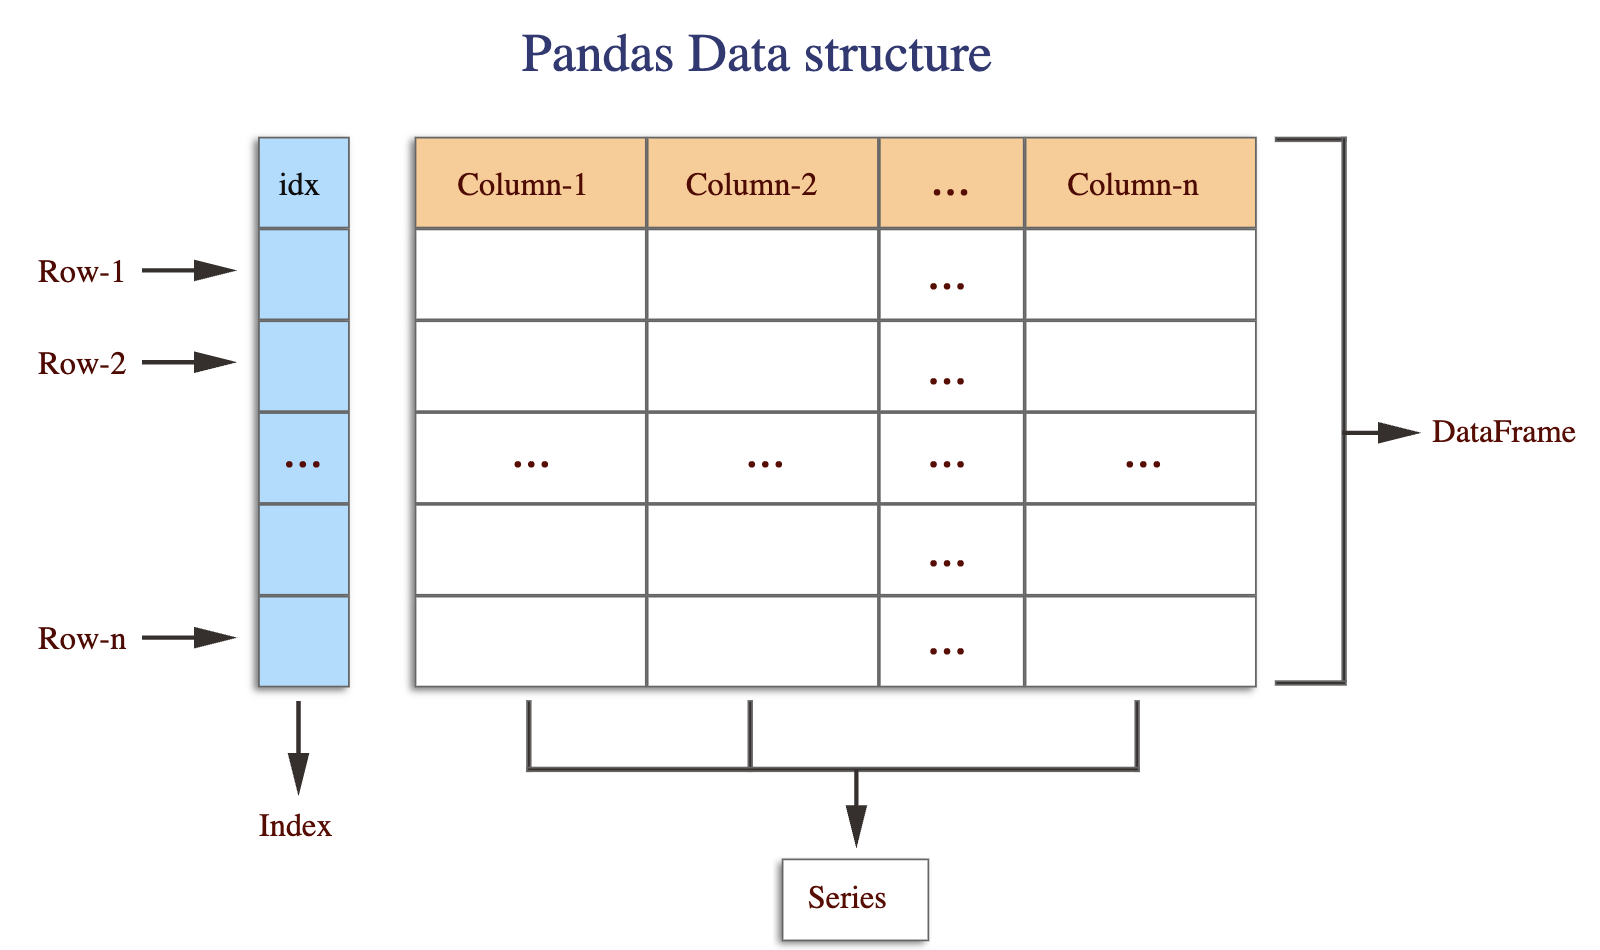

* Pandas = **DataFrame, Series and Panel**. (Note there is a `s` at the end of Pandas.)
* Pandas is built on top of NumPy. So it has lots of the features in NumPy.
* But Pandas can do a lot more.  It can handle elements with different datatypes or missing data.
* In the table above, each column is like a NumPy array with its own data type.

### Basics of Pandas
Pandas has two or three main data types:
* Series (similar to numpy arrays, but with indices)
* DataFrames (similar to spreadsheet, with a Series in each column; commonly used)
* Panels (3D version of DataFrame, not as commonly used)

### Import the Pandas package 

In [ ]:
# import packages
import pandas as pd    # In standard notation, use pd for pandas

# Extra packages
import numpy as np
import matplotlib.pyplot as plt # for plotting

## 2. Series object in Pandas 
Pandas [Series](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html) is basically a one-dimensional array.  It can be created from a list or an array. You can treat Pandas Series the 
same way as Pandas array (indexing, slicing, etc.)

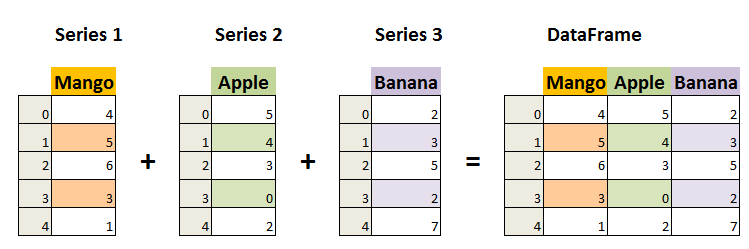

Missing or illegal data can be expressed as **NaN** (Not a Number).  This is particularly useful because we often have missing values in the data, but we still want the code to run.

In [ ]:
s=pd.Series("float64")
print(s)

In [ ]:
s = pd.Series([1,3,5,np.nan,6,8])  # np.nan = missing data
print(s)     # prints series s along with the index
print(type(s))

In Pandas, we can use methods similar to those in NumPy:

In [ ]:
# Return Series as ndarray or ndarray-like depending on the dtype.
print(s.values)

# Number of dimensions of the underlying data, by definition 1.
print(s.ndim) 

# Return a tuple of the shape of the underlying data.
print(s.shape) 

# Return the number of elements in the underlying data.
print(s.size) 

In [ ]:
# Index
s[2]  

In [ ]:
# Slicing
s[1:4] 

### Create a Series from dict
A dict can be passed as input and if no index is specified, then the dictionary keys are taken in a sorted order to construct index. If index is passed, the values in data corresponding to the labels in the index will be pulled out.


In [ ]:
# Observe − Dictionary keys are used to construct index.
data = {'a' : 0., 'b' : 1., 'c' : 2.}
s = pd.Series(data)
print (s)

In [ ]:
# Index order is persisted and the missing element is filled with NaN (Not a Number).
data = {'a' : 0., 'b' : 1., 'c' : 2.}
s = pd.Series(data, index=['b','c','d','a'])
print (s)

In [ ]:
# Length must be the same
s = pd.Series([1,2,3,4], index=['b','c','d','a']) 
print (s)

### Explicit and implicit indexers - loc and iloc

Dataframe has two choices of locating the values by index.

* `loc` is for **explicit** index; **get a section BY RANGE of the index**
* `iloc` is for **implicit** index; the `i` in `iloc` stands for implicit, **get a section by POSITION**

The following will explain the difference between explicit and implicit index


In [ ]:
data = pd.Series(['a', 'b', 'c'], index=[1, 3, 5])
data

In [ ]:
# Explicit index (1,3,5) when indexing
data[1]

In [ ]:
# Implicit index when slicing
# The implicit index for the array is 0, 1, 2 
#   corresponding to 'a', 'b', 'c' 
data[1:3]

This could be confusing. To clarify this problem, we use `loc` to mean explicit indexing, and `iloc` to mean implicit indexing.

General rule: **using explicit loc is better than using implicit iloc**

In [ ]:
# Explicit loc indexing
data.loc[1]

In [ ]:
# Explicit loc slicing
data.loc[1:3] 
# From 1 to 3 in the specified index, just what you expected

The explicit indexer `loc` is very clear, without the quirkiness of 'up to but not including'. So **use `loc` whenever the index is complicated**

Now for implicit indexing - `iloc`:

In [ ]:
# implicit iloc for indexing
# Remember, the implicit index are 0, 1, 2
data.iloc[1]

In [ ]:
# implicit iloc for slicing
# Again, the quirky from 1 to (but not including) 3
data.iloc[1:3]

If implicit indexing is used, a user has to stop and think, even for simple cases like this.

If explicit indexing is used, like the examples above, things are rather intuitive.

### More generalization of Series in Pandas

Series has lots of attributes and methods. We will only cover a few commonly used methods. Please check the link above if necessary.

#### `argsort()`

`argsort()` return the integer indices that would sort the Series values.

In [ ]:
ss = [1,5,3,6,8]
ss.sort()
print(ss)

s = pd.Series([1,5,3,6,8])  
print(s.argsort())

#### `concat()`

`concat()` concatenate two or more Series. 

In [ ]:
s1 = pd.Series([1,5,3,6,8])  
s2 = pd.Series([9,12,11])  

s = pd.concat([s1, s2])
print(s)
print(s.loc[0])

# ignore_index: if True, do not use the index values along the concatenation axis. 
# The resulting axis will be labeled 0, …, n - 1.
s = pd.concat([s1, s2], ignore_index=True)
print(s)
print(s.loc[0])


# In pandas 2.0, append() has been removed. Before this version it works.
# s1 = pd.Series([1,5,3,6,8])  
# s2 = pd.Series([9,12,11])  
# print(s1.append(s2, ignore_index=True))

## 3. DataFrame object in Pandas

We use `pd.DataFrame(**inputs**)` to create a DataFrame; we can insert almost any data type as an argument.

We can treat each column like a separate Series. 

In [ ]:
# We use label to separate the data.
df1 = pd.DataFrame({'label': ['A', 'B', 'C', 'A', 'B', 'C'],
                   'value': [1, 2, 3, 4, 5, 6]})
print(df1)

In [ ]:
print(type(df1))

In [ ]:
# Can access a particular column 
df1['label']

In [ ]:
# Can convert label to lower case
df1['label'].str.lower()

In [ ]:
# Similarly, we can access the 'value' column
df1['value']

In [ ]:
# sum up the value column
print('sum', df1['value'].sum())

### Using dictionary to construct a (two-dimensional) DataFrame object

The Ohio's population in 2000 is 1.5 (in some unit); its population in 2001 is 1.7. 

These data are made up. Ohio actually has a lot more people than Nevada.

In [ ]:
data = {'state': ['Ohio', 'Washington', 'New York', 'California', 'Nevada'], 
        'year': [2000, 2001, 2002, 2001, 2002],
        'pop': [1.5, 1.7, 3.6, 2.4, 2.9]
      }

In [ ]:
print(data)

In [ ]:
print(type(data)) # yup, the data is a dictionary

In [ ]:
# From the data, create a DataFrame named df2
df2 = pd.DataFrame(data)
print(df2)

In [ ]:
# Check the data type of each column
df2.dtypes 

The dtype object comes from NumPy, it describes the type of element in a ndarray. Every element in an ndarray must have the same size in bytes. For int64 and float64, they are 8 bytes. But for strings, the length of the string is not fixed. So instead of saving the bytes of strings in the ndarray directly, Pandas uses an object ndarray, which saves pointers to objects; because of this the dtype of this kind ndarray is object.

In [ ]:
# Be a little silly
df2 = df2.rename(columns = {'year':'hahahah'})
print(df2)

In [ ]:
df2.index = df2.state
print(df2)
# print(df2.loc['Ohio'])

### Explicit and implicit indexers - loc and iloc
#### `.loc()`

In [ ]:
# Getting a cross section with .loc - BY VALUES of the index and columns
# df.loc[a:b, x:y], by rows and column location

# Note: You have to know indices and columns

df2.loc['California':'Nevada',
        'hahahah':'pop']

#### `.iloc()`

In [ ]:
df2.columns

In [ ]:
# .iloc slicing at specific location - BY POSITION in the table
# Recall:
# df2[a:b] by rows
# df2[[col]] or df[[col1, col2]] by columns
# df2.loc[a:b, x:y], by index and column values + location
# df2.iloc[3:5,0:2], numeric position in table

df2.iloc[1:4,0:2] # 2nd to 4th row, 1st to 2nd column

In [ ]:
# Data only from row with index value '3'
print (df2.iloc[3])

In [ ]:
# iloc will accept a range with ':', just like numpy
df2.iloc[1:3,:]

In [ ]:
# Can also return specific value
print (df2.iloc[2,1])
# Same as above but faster for one single scaler value
print (df2.iat[2,1])

## 4. Example Case: Import and inspect data 
In this case, we will analyze a ready-made dataset by [Gapminder](https://www.gapminder.org/).

More data can be found [here](https://www.gapminder.org/data/).

In [ ]:
import pandas as pd 

In [ ]:
# a common way to import the "ready-made" or harvested data, normally in csv format 
# the data file used in this tutorial is from this tutorial: "https://storage.googleapis.com/learn_pd_like_tidyverse/gapminder.csv"
# special thanks for the original author for compiling and sharing this dataset 

gapminder = pd.read_csv('data/gapminder_cleaned_2.csv')

Using Excel, open this csv file and check its contents. Be careful that you don't make changes to this csv file in Excel. A safe way is to make a copy of the csv file, and then open the copy with Excel.

**Note**: reading and writing (external) data with Pandas (Nelli, 2018, p. 142) 

<div align="center">
	<img src="img/ch13.pd_IO.png" width="30%">
</div>

In [ ]:
# Checkin the type and take a glance at the head 
print(type(gapminder))

# Show the first 5 (defaut) rows of data
gapminder.head() 

In [ ]:
# Show the last 10 rows of data
gapminder.tail(10)   

In [ ]:
# Randomly show the 10 rows of data
gapminder.sample(10)

### Examining the attributes of the Data Frame (standard procedures)

- ```df.info()```
- ```df.shape``` 
- ```df.columns``` (check the variables) 
- ```df.index``` (check the index of the "rows") 
- ```df.describe()``` (descriptive statistics for numerical variables) 
- Note that methods (functions) have parentheses, and attributes (values) don't. 

In [ ]:
# Shows info of the columns (name and data type) and
# number of rows (compare with results from the tail() command)
gapminder.info()

In [ ]:
# (the number of cases/observations/rows, the number of variables/columns)
gapminder.shape 

In [ ]:
gapminder.columns

In [ ]:
gapminder.index

In [ ]:
# Show the statistics of the data
gapminder.describe()

In [ ]:
gapminder.describe().loc['count',:]

### Case selection 

#### Selecting cases (rows/observations) using Boolean indexing

Reference for Boolean indexing or masking: VanderPlas 3.2 Data indexing and selection, search for 'masking'

In [ ]:
gapminder['country']=="China"

In [ ]:
# Select all data with 'country'=='China'
# In previous line, the first gapminder refers to the DataFrame name,
# and gapminder['country'] refers to the column country.
gapminder[gapminder['country']=="China"] 

In [ ]:
# Show all data with year 2007 AND continent Asia
# Verify in the result that year==2007 and continent==Asia
gapminder[(gapminder['year'] == 2007) & (gapminder['continent'] == 'Asia')]

#### Using a variable list to select multiple variables 

In [ ]:
# Input the list ['country', 'continent'] to the Data Frame 
gapminder[['country', 'continent']].head(20)

### Basic statistics 

We briefly mentioned .describe() earlier. Now let's discuss this in more detail.

In [ ]:
# A quick way to get statistics
gapminder.describe()  

As said above, it's better to use the explicit indexing `loc` rather than the implicit `iloc`. Here using the explicit `.loc`, we get the data of the specific variables we listed; no quirky stuff.

In [ ]:
# Calculations from all the data.
# These results are the same as those in gapminder.describe()
gapminder.describe().loc[['mean','std'],['lifeExp','gdpPercap']]

In [ ]:
# Now let's consider the data for Asia
gapminder[gapminder['continent']=='Asia'].describe().\
loc[['mean','std'],['lifeExp','gdpPercap']]

In [ ]:
# Europe has higher life expectancy
gapminder[gapminder['continent']=='Europe'].describe().\
loc[['mean','std'],['lifeExp','gdpPercap']]

In [ ]:
# And Africa has very low life expectancy
gapminder[gapminder['continent']=='Africa'].describe().\
loc[['mean','std'],['lifeExp','gdpPercap']]

### Group By: split-apply-combine

Any groupby operation involves one of the following operations on the original object. They are

- Splitting the Object
- Applying a function
- Combining the results

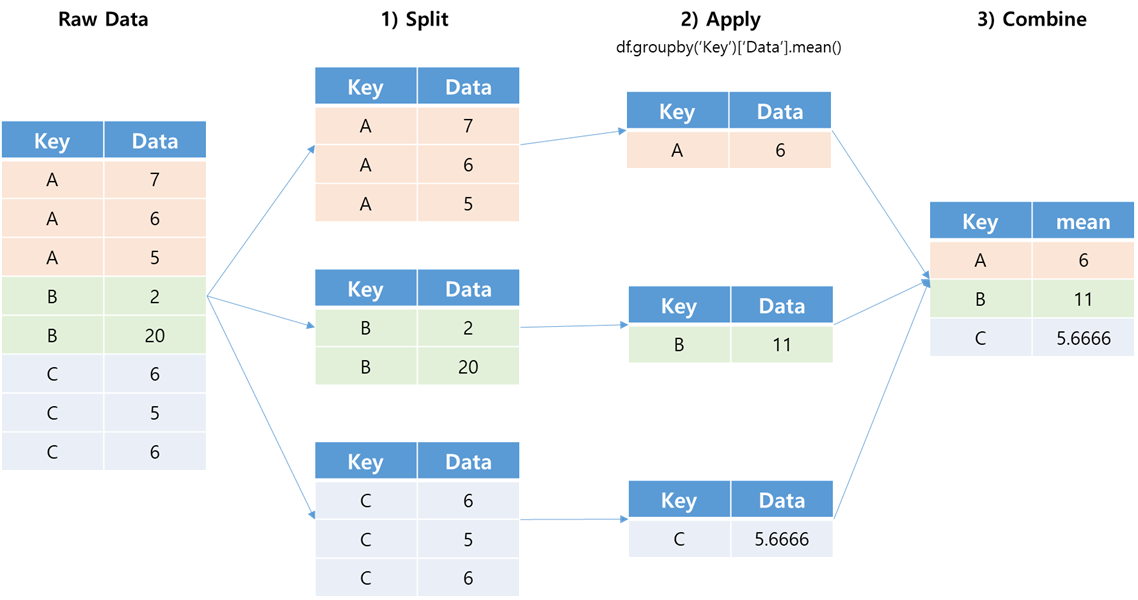

For example, we will compute the mean lifeExp and gdpPercap of different groups:

In [ ]:
# And continet
gapminder.groupby(by = 'continent')[['lifeExp', 'gdpPercap']].mean()

In [ ]:
# And by year
gapminder.groupby(by = 'year')[['lifeExp', 'gdpPercap']].mean()

### Create new columns derived from existing columns

In [ ]:
# create a new column from two columns: pop and gdpPercap
gapminder["totalGdp"]=gapminder["pop"]*gapminder["gdpPercap"]
gapminder.head(5)

### Merge DataFrame

A merge() function allow updating the content of one DataFrame with the content from another DataFrame.

In [ ]:
import pandas as pd
data1 = {"name": ["Sally", "Mary", "John"],
         "age": [50, 40, 30]}

data2 = {"name": ["Sally", "Peter", "Micky"],
         "age": [50, 44, 22]}

df1 = pd.DataFrame(data1)
df2 = pd.DataFrame(data2)

newdf = pd.merge(df1, df2)
newdf

In [ ]:
# 'how' specifies how to merge, default 'inner'. 
newdf = pd.merge(df1, df2, how='right')
newdf

In [ ]:
newdf = pd.merge(df1, df2, how='left')
newdf

In [ ]:
newdf = pd.merge(df1, df2, how='outer')
newdf

## Tasks

#### Task 1:

In the code cell below, complete the function `passScore` which takes a series `s` as an argument, and returns a series which contains all values greater than the given integer `p`.

#### Task 2:  

In the code cell below, complete the function `addTotal` which takes a DataFrame `df` with columns `'Item'`, `'Price'`, and `'Quantity'`. The function should:

- Add a new column `'TotalCost'` calculated as `Price * Quantity`.

- Sort the DataFrame by `'TotalCost'` in descending order.

- Reset the DataFrame index (from 0 to n-1).

- Return the resulting DataFrame.

#### Task 3: 

In the code cell below, complete the function `getTotalSales` which takes a DataFrame `df` containing `'Category'` and `'Sales'` columns. The function groups the data by `'Category'`, calculates the sum of sales for each category, and returns a new DataFrame with columns `'Category'` and `'Sales'`. Reset the DataFrame index (0 to n-1).

#### Task 4: 

In the code cell below, complete the function `filterValidOrders` which takes two DataFrames as inputs: `orders` (containing columns `'OrderID'`, `'ProductID'`, and `'Quantity'`) and `products` (containing columns `'ProductID'` and `'MinQuantity'`). The function merges `orders` and `products` on `'ProductID'` and returns a new DataFrame containing only the merged rows where `'Quantity'` is greater than or equal to `'MinQuantity'`. Reset the DataFrame index (0 to n-1).

Example:

Input: orders = `pd.DataFrame({'OrderID': [101, 102, 103, 104], 'ProductID': ['P1', 'P2', 'P1', 'P3'], 'Quantity': [5, 2, 12, 8]})`, illustrated as:
                    
| OrderID | ProductID | Quantity| 
| --- | --- | --- |
| 101 | P1 | 5 |
| 102 | P2 | 2 | 
| 103 | P1 | 12 |
| 104 | P3 | 8 |

products = `pd.DataFrame({'ProductID': ['P1', 'P2', 'P3'],'minQuantity': [10, 5, 5]})`, illustrated as:

| ProductID | minQuantity |
| --- | --- |
| P1 | 10 |
| P2 | 5 |
| P3 | 5 |

Output: `pd.DataFrame({'OrderID': [103, 104], 'ProductID': ['P1', 'P3'], 'Quantity': [12, 8], 'MinQuantity': [10, 5]})`, illustrated as:

| OrderID | ProductID | Quantity| minQuantity |
| --- | --- | --- | --- |
| 103 | P1 | 12 | 10 |
| 104 | P3 | 8 | 5|

*Note that 'reset_index(drop=True)' may need for reset the indices for newly creately DataFrames.*

#### Task 5: 

In the code cell below, complete the function `zeroColumnMax` which takes a DataFrame `df` as an argument and returns a new DataFrame. The new DataFrame retains the same index and column labels as `df`. For each column, find its maximum value and set all occurrences of that maximum value in the column to `0`. All other elements remain unchanged.

#### Task 6: 

In the code cell below, complete the function `zeroOutliersIQR` which takes a DataFrame `df` containing numeric columns. For each column, calculate the Interquartile Range: $\text{IQR} = Q3 - Q1$, which is a statistical measure of variability that represents the spread of the middle 50% of a dataset, $Q_3$ being the 75th percentile and $Q_1$ being the 25th percentile. An element is considered an outlier if it is strictly less than $Q1 - 1.5 \times \text{IQR}$ or strictly greater than $Q3 + 1.5 \times \text{IQR}$. The function should return a new DataFrame where all outliers in any column are replaced with `0`, while non-outliers remain unchanged.